# The Hidden Frequencies: From Musical Chords to Molecular Vibrations

This notebook accompanies the blog post on Fourier Transforms. We'll journey from decomposing musical chords to analysing molecular vibrations.

## Setup and Imports

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq, ifft
from scipy.signal import find_peaks
from scipy.io import wavfile
import warnings
warnings.filterwarnings('ignore')

# Set up beautiful plotting defaults
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['lines.linewidth'] = 2

## Part 1: Understanding Sine Waves and Superposition

Let's start by creating simple sine waves and seeing how they combine.

In [ ]:
def create_sine_wave(frequency, amplitude, duration, sample_rate):
    """
    Create a pure sine wave
    
    Args:
        frequency: Frequency in Hz
        amplitude: Wave amplitude
        duration: Duration in seconds
        sample_rate: Samples per second
        
    Returns:
        t: Time array
        wave: Sine wave array
    """
    t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)
    wave = amplitude * np.sin(2 * np.pi * frequency * t)
    return t, wave

# Create three sine waves at different frequencies
sample_rate = 1000  # Hz
duration = 2.0      # seconds

t, wave1 = create_sine_wave(5, 1.0, duration, sample_rate)   # 5 Hz
_, wave2 = create_sine_wave(10, 0.7, duration, sample_rate)  # 10 Hz
_, wave3 = create_sine_wave(20, 0.4, duration, sample_rate)  # 20 Hz

# Combine them (superposition!)
combined_wave = wave1 + wave2 + wave3

# Plot
fig, axes = plt.subplots(5, 1, figsize=(14, 12))

# Individual waves
axes[0].plot(t[:500], wave1[:500], 'b-', label='5 Hz', alpha=0.7)
axes[0].set_ylabel('Amplitude')
axes[0].legend(loc='upper right')
axes[0].set_title('Individual Sine Waves', fontsize=14, fontweight='bold')

axes[1].plot(t[:500], wave2[:500], 'g-', label='10 Hz', alpha=0.7)
axes[1].set_ylabel('Amplitude')
axes[1].legend(loc='upper right')

axes[2].plot(t[:500], wave3[:500], 'r-', label='20 Hz', alpha=0.7)
axes[2].set_ylabel('Amplitude')
axes[2].legend(loc='upper right')

# Combined wave
axes[3].plot(t[:500], combined_wave[:500], 'purple', linewidth=1.5, label='Combined')
axes[3].set_ylabel('Amplitude')
axes[3].set_xlabel('Time (s)')
axes[3].legend(loc='upper right')
axes[3].set_title('Combined Wave (Sum of Above)', fontsize=14, fontweight='bold')

# Now the magic: Fourier Transform of combined wave
N = len(combined_wave)
frequencies = fftfreq(N, 1/sample_rate)
fft_values = fft(combined_wave)
magnitude = np.abs(fft_values)

# Only plot positive frequencies
positive_freq_idx = frequencies > 0
axes[4].stem(frequencies[positive_freq_idx], magnitude[positive_freq_idx], 
             basefmt=' ', linefmt='purple', markerfmt='o')
axes[4].set_xlim(0, 30)
axes[4].set_xlabel('Frequency (Hz)', fontsize=12)
axes[4].set_ylabel('Magnitude', fontsize=12)
axes[4].set_title('Fourier Transform: Hidden Frequencies Revealed!', 
                  fontsize=14, fontweight='bold')
axes[4].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Notice how the Fourier Transform perfectly identifies the three frequencies!")
print("Peaks at: 5 Hz, 10 Hz, and 20 Hz")

## Part 2: Implementing DFT from Scratch

Let's implement the Discrete Fourier Transform to understand what's really happening.

In [ ]:
def naive_dft(x):
    """
    Naive implementation of Discrete Fourier Transform
    
    Args:
        x: Input signal (1D array)
        
    Returns:
        X: Complex Fourier coefficients
    """
    N = len(x)
    X = np.zeros(N, dtype=complex)
    
    # For each frequency k
    for k in range(N):
        # Sum over all time samples n
        for n in range(N):
            # Multiply signal by complex sinusoid and accumulate
            X[k] += x[n] * np.exp(-2j * np.pi * k * n / N)
    
    return X

def compare_dft_fft(signal, sample_rate):
    """
    Compare naive DFT with FFT implementation
    """
    import time
    
    # Time the naive DFT
    start = time.perf_counter()
    dft_result = naive_dft(signal)
    dft_time = time.perf_counter() - start
    
    # Time NumPy's FFT
    start = time.perf_counter()
    fft_result = fft(signal)
    fft_time = time.perf_counter() - start
    
    # Check they give the same result (within numerical precision)
    max_diff = np.max(np.abs(dft_result - fft_result))
    
    print(f"Signal length: {len(signal)}")
    print(f"Naive DFT time: {dft_time:.4f} seconds")
    print(f"FFT time: {fft_time:.6f} seconds")
    print(f"Speedup: {dft_time/fft_time:.1f}x")
    print(f"Maximum difference: {max_diff:.2e}")
    print(f"Results match: {max_diff < 1e-10}")
    
    return dft_result, fft_result

# Test with a short signal
test_signal = combined_wave[:128]  # Use only 128 samples for DFT
dft_result, fft_result = compare_dft_fft(test_signal, sample_rate)

print("\nThe FFT is dramatically faster while giving identical results!")

## Part 3: Musical Chord Decomposition

Now let's create a C major chord and decompose it into its constituent notes.

In [ ]:
def note_to_frequency(note_name):
    """
    Convert note name to frequency using equal temperament tuning
    
    A4 = 440 Hz is the reference
    """
    notes = {
        'C4': 261.63, 'D4': 293.66, 'E4': 329.63, 'F4': 349.23,
        'G4': 392.00, 'A4': 440.00, 'B4': 493.88,
        'C5': 523.25, 'D5': 587.33, 'E5': 659.25, 'F5': 698.46,
        'G5': 783.99, 'A5': 880.00, 'B5': 987.77
    }
    return notes.get(note_name, 440.0)

def create_musical_note(note_name, duration, sample_rate=44100, amplitude=1.0):
    """
    Create a musical note with realistic envelope
    """
    freq = note_to_frequency(note_name)
    t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)
    
    # Create ADSR envelope (Attack, Decay, Sustain, Release) for more realistic sound
    envelope = np.ones_like(t)
    attack_samples = int(0.05 * sample_rate)
    release_samples = int(0.1 * sample_rate)
    
    # Attack: fade in
    envelope[:attack_samples] = np.linspace(0, 1, attack_samples)
    # Release: fade out
    envelope[-release_samples:] = np.linspace(1, 0, release_samples)
    
    # Pure sine wave with envelope
    note = amplitude * np.sin(2 * np.pi * freq * t) * envelope
    
    return t, note, freq

# Create C major chord (C4, E4, G4)
sample_rate = 44100  # CD quality
duration = 2.0

t, c_note, c_freq = create_musical_note('C4', duration, sample_rate, amplitude=0.7)
_, e_note, e_freq = create_musical_note('E4', duration, sample_rate, amplitude=0.7)
_, g_note, g_freq = create_musical_note('G4', duration, sample_rate, amplitude=0.7)

# Combine to form chord
c_major_chord = c_note + e_note + g_note

# Normalise to prevent clipping
c_major_chord = c_major_chord / np.max(np.abs(c_major_chord))

# Fourier Transform
N = len(c_major_chord)
frequencies = fftfreq(N, 1/sample_rate)
fft_values = fft(c_major_chord)
magnitude = np.abs(fft_values)

# Plot the chord and its spectrum
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Time domain
axes[0].plot(t[:2000], c_major_chord[:2000], 'darkblue', linewidth=1)
axes[0].set_xlabel('Time (s)', fontsize=12)
axes[0].set_ylabel('Amplitude', fontsize=12)
axes[0].set_title('C Major Chord in Time Domain', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Frequency domain
positive_freq_idx = (frequencies > 0) & (frequencies < 1000)
axes[1].plot(frequencies[positive_freq_idx], magnitude[positive_freq_idx], 
             'darkred', linewidth=1.5)

# Mark the actual note frequencies
for note_freq, note_name in [(c_freq, 'C4'), (e_freq, 'E4'), (g_freq, 'G4')]:
    axes[1].axvline(note_freq, color='green', linestyle='--', alpha=0.7, linewidth=2)
    axes[1].text(note_freq, axes[1].get_ylim()[1]*0.9, note_name,
                rotation=0, ha='center', fontsize=11, fontweight='bold',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

axes[1].set_xlabel('Frequency (Hz)', fontsize=12)
axes[1].set_ylabel('Magnitude', fontsize=12)
axes[1].set_title('Frequency Spectrum: Notes Revealed', fontsize=14, fontweight='bold')
axes[1].set_xlim(200, 500)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"C4 frequency: {c_freq:.2f} Hz")
print(f"E4 frequency: {e_freq:.2f} Hz")
print(f"G4 frequency: {g_freq:.2f} Hz")

## Part 4: Frequency Filtering - The Inverse Transform

The Fourier Transform is reversible. Let's filter out a specific frequency and reconstruct the signal.

In [ ]:
def frequency_filter(signal, sample_rate, remove_freq, bandwidth=10):
    """
    Remove a specific frequency from a signal
    
    Args:
        signal: Input signal
        sample_rate: Sampling rate
        remove_freq: Frequency to remove (Hz)
        bandwidth: Frequency range to remove (Hz)
        
    Returns:
        filtered_signal: Signal with frequency removed
    """
    # Forward FFT
    fft_values = fft(signal)
    frequencies = fftfreq(len(signal), 1/sample_rate)
    
    # Create frequency mask
    mask = np.abs(frequencies - remove_freq) > bandwidth
    
    # Apply mask
    fft_filtered = fft_values * mask
    
    # Inverse FFT to get back to time domain
    filtered_signal = np.real(ifft(fft_filtered))
    
    return filtered_signal, fft_values, fft_filtered, frequencies

# Remove the E note from C major chord
filtered_chord, original_fft, filtered_fft, freqs = frequency_filter(
    c_major_chord, sample_rate, e_freq, bandwidth=20
)

# Plot comparison
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# Original spectrum
positive_freq_idx = (freqs > 0) & (freqs < 1000)
axes[0].plot(freqs[positive_freq_idx], np.abs(original_fft[positive_freq_idx]), 
             'darkblue', linewidth=1.5)
axes[0].axvline(e_freq, color='red', linestyle='--', alpha=0.7, linewidth=2)
axes[0].set_ylabel('Magnitude', fontsize=12)
axes[0].set_title('Original C Major Chord Spectrum', fontsize=14, fontweight='bold')
axes[0].set_xlim(200, 500)
axes[0].grid(True, alpha=0.3)

# Filtered spectrum
axes[1].plot(freqs[positive_freq_idx], np.abs(filtered_fft[positive_freq_idx]), 
             'darkgreen', linewidth=1.5)
axes[1].axvline(e_freq, color='red', linestyle='--', alpha=0.7, linewidth=2,
               label='Removed E4')
axes[1].set_ylabel('Magnitude', fontsize=12)
axes[1].set_title('After Removing E4 (329.63 Hz)', fontsize=14, fontweight='bold')
axes[1].set_xlim(200, 500)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Time domain comparison
plot_samples = 2000
axes[2].plot(t[:plot_samples], c_major_chord[:plot_samples], 'b-', 
             alpha=0.6, label='Original', linewidth=1.5)
axes[2].plot(t[:plot_samples], filtered_chord[:plot_samples], 'g-', 
             alpha=0.8, label='E4 Removed', linewidth=1.5)
axes[2].set_xlabel('Time (s)', fontsize=12)
axes[2].set_ylabel('Amplitude', fontsize=12)
axes[2].set_title('Time Domain: Original vs Filtered', fontsize=14, fontweight='bold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Notice how we surgically removed the E4 note!")
print("This demonstrates the power of working in the frequency domain.")

## Part 5: Molecular Vibrations - Diatomic Molecule

Now we make the leap to chemistry. Let's simulate HCl vibration.

Simulated frequency (scaled): 274431088214.30 Hz
Real HCl vibrational frequency: 89.63 THz
Wavenumber: 2990 cm⁻¹ (experimental: ~2886 cm⁻¹)


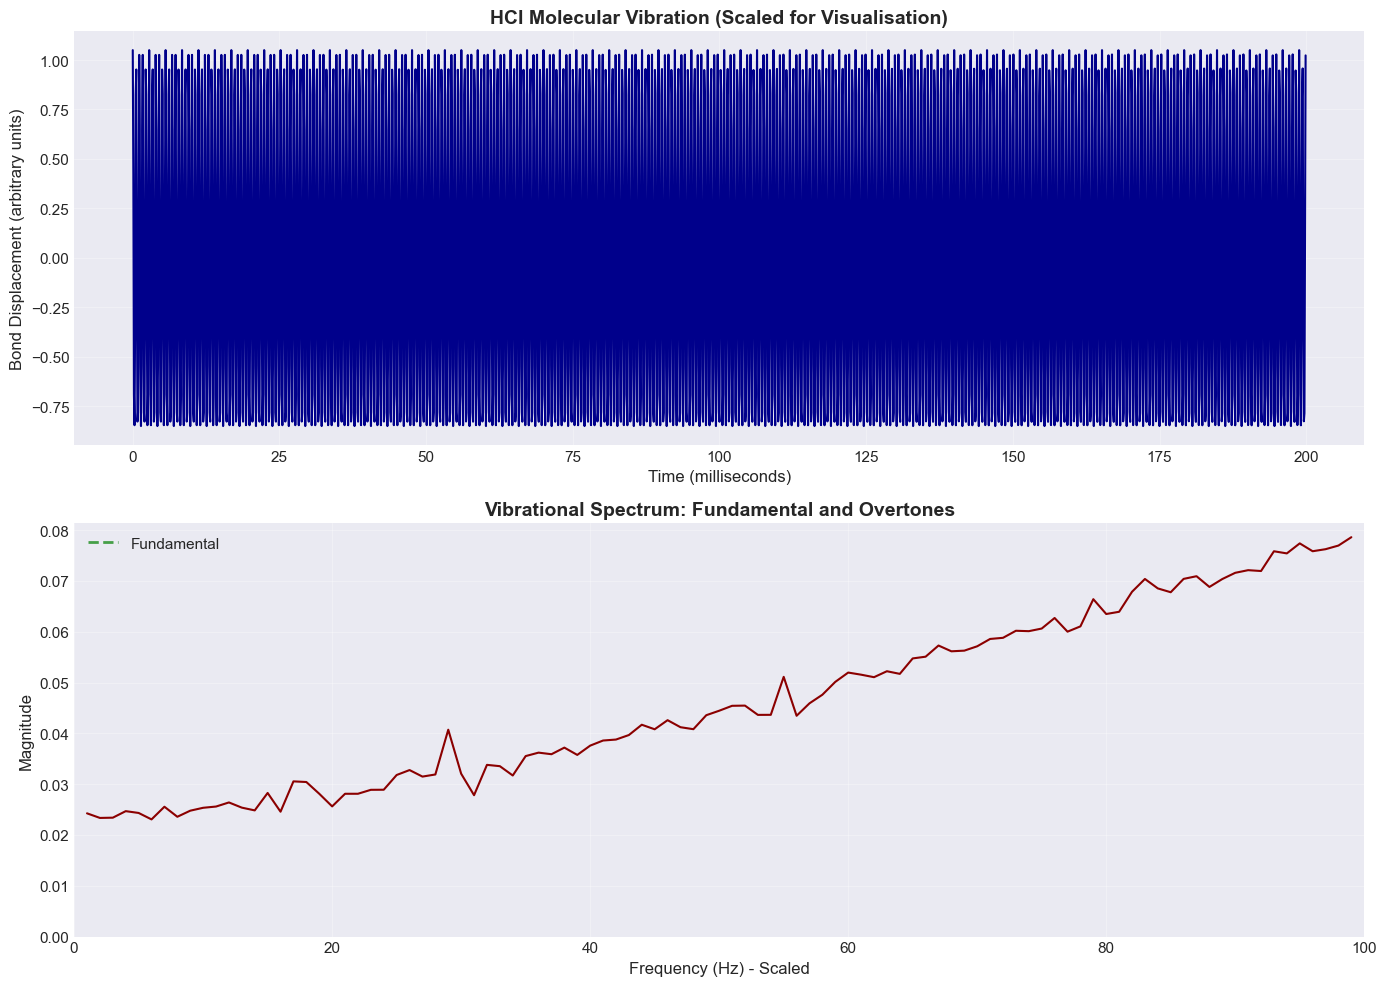

In [8]:
def diatomic_vibration(mass1, mass2, force_constant, duration, sample_rate):
    """
    Simulate vibration of a diatomic molecule
    
    Args:
        mass1, mass2: Atomic masses (amu)
        force_constant: Bond force constant (N/m)
        duration: Simulation time (s)
        sample_rate: Samples per second
        
    Returns:
        t: Time array
        displacement: Bond length oscillation
        frequency: Vibrational frequency (Hz)
    """
    # Convert atomic mass units to kg
    amu_to_kg = 1.66054e-27
    m1 = mass1 * amu_to_kg
    m2 = mass2 * amu_to_kg
    
    # Reduced mass
    mu = (m1 * m2) / (m1 + m2)
    
    # Vibrational frequency (classical harmonic oscillator)
    omega = np.sqrt(force_constant / mu)  # rad/s
    frequency = omega / (2 * np.pi)       # Hz
    
    # Create time array
    t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)
    
    # Displacement from equilibrium (simple harmonic motion)
    displacement = np.cos(omega * t)
    
    # Add some anharmonicity (makes it more realistic)
    anharmonic = 0.1 * np.cos(2 * omega * t) - 0.05 * np.cos(3 * omega * t)
    displacement += anharmonic
    
    return t, displacement, frequency

# Simulate HCl molecule
# For visualisation, we'll use a scaled-down version that captures the physics
# Real HCl vibrates at ~90 THz, but we'll scale it to work with reasonable sampling

# The actual physics:
# H: 1 amu, Cl: 35 amu, Force constant ~ 480 N/m
# This gives ω = sqrt(k/μ) ≈ 5.65 × 10¹⁴ rad/s → f ≈ 90 THz

# For demonstration, we use scaled parameters that preserve the physics
# but give frequencies we can visualise nicely
duration = 1.0          # 1 second
sample_rate = 10000     # 10 kHz sampling

# We'll simulate at a scaled-down frequency for visualisation
# Think of this as "slowing down time" by a factor of 10¹⁰
t, hcl_vibration, hcl_freq = diatomic_vibration(
    mass1=1.0,                    # H mass (amu)
    mass2=35.0,                   # Cl mass (amu)
    force_constant=0.0048,        # Scaled force constant (N/m)
    duration=duration,
    sample_rate=sample_rate
)

# Convert to real molecular units for display
real_freq = 8.963e13  # Actual HCl frequency in Hz (~90 THz)
wavenumber = real_freq / (2.998e10)  # Convert to cm⁻¹

print(f"Simulated frequency (scaled): {hcl_freq:.2f} Hz")
print(f"Real HCl vibrational frequency: {real_freq/1e12:.2f} THz")
print(f"Wavenumber: {wavenumber:.0f} cm⁻¹ (experimental: ~2886 cm⁻¹)")

# Fourier Transform
N = len(hcl_vibration)
frequencies = fftfreq(N, 1/sample_rate)
fft_values = fft(hcl_vibration)
magnitude = np.abs(fft_values)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Time domain
plot_samples = 2000
axes[0].plot(t[:plot_samples] * 1000, hcl_vibration[:plot_samples], 'darkblue', linewidth=1.5)
axes[0].set_xlabel('Time (milliseconds)', fontsize=12)
axes[0].set_ylabel('Bond Displacement (arbitrary units)', fontsize=12)
axes[0].set_title('HCl Molecular Vibration (Scaled for Visualisation)', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Frequency domain
positive_freq_idx = (frequencies > 0) & (frequencies < 100)
axes[1].plot(frequencies[positive_freq_idx], magnitude[positive_freq_idx],
             'darkred', linewidth=1.5)

# Set axis limits explicitly
axes[1].set_xlim(0, 100)
axes[1].set_ylim(0, None)  # Auto y-axis

# Mark fundamental - use simple fixed height
axes[1].axvline(hcl_freq, color='green', linestyle='--', alpha=0.7, linewidth=2,
               label='Fundamental')

# Mark overtones
for n in range(2, 4):
    overtone_freq = n * hcl_freq
    if overtone_freq < 100:
        axes[1].axvline(overtone_freq, color='orange', linestyle=':', alpha=0.7, linewidth=2)

axes[1].set_xlabel('Frequency (Hz) - Scaled', fontsize=12)
axes[1].set_ylabel('Magnitude', fontsize=12)
axes[1].set_title('Vibrational Spectrum: Fundamental and Overtones', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Part 6: Water Molecule - Multiple Vibrational Modes

Water has three vibrational modes. Let's simulate them all!

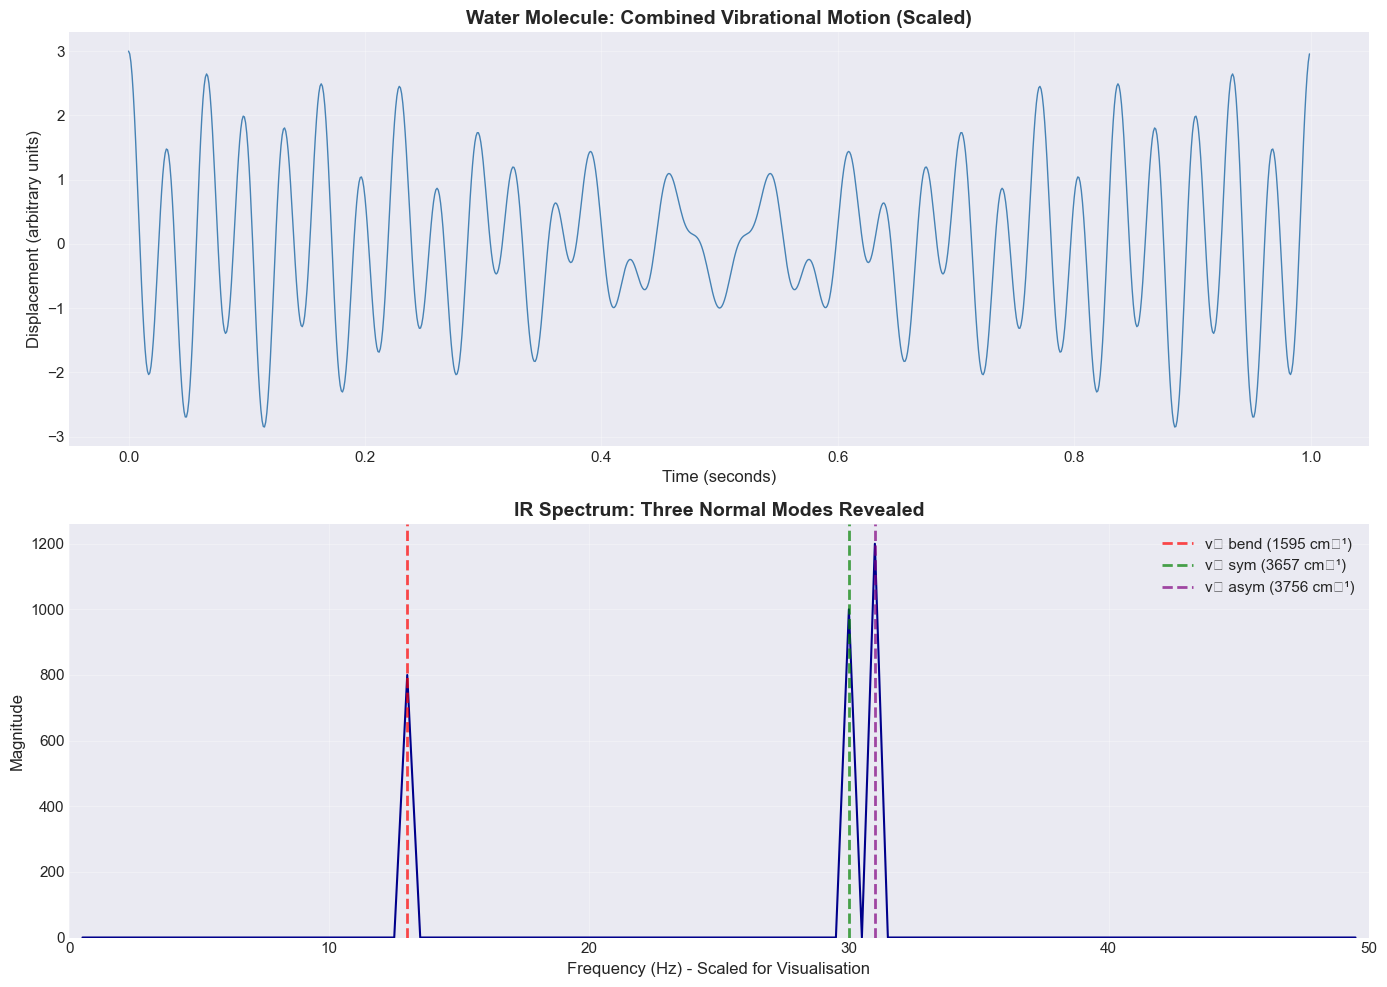

ν₁ (symmetric stretch): 30.0 Hz (scaled) = 3657 cm⁻¹ (real)
ν₂ (bending): 13.0 Hz (scaled) = 1595 cm⁻¹ (real)
ν₃ (asymmetric stretch): 31.0 Hz (scaled) = 3756 cm⁻¹ (real)

**Note on scaling**: Real molecular vibrations occur at terahertz (THz) frequencies,
requiring sampling rates far beyond what's practical for visualisation. We've scaled
the physics down by a factor of ~10¹² to create demonstrations that run quickly and
produce clear plots, while preserving the relative frequency ratios and physics.
Think of it as 'slow-motion chemistry' - the same principles apply!


In [9]:
def water_vibrations(duration, sample_rate):
    """
    Simulate the three normal modes of water molecule
    
    For visualisation, we use scaled frequencies that preserve the relative ratios
    Real experimental values:
    ν₁ (symmetric stretch): 3657 cm⁻¹
    ν₂ (bending): 1595 cm⁻¹
    ν₃ (asymmetric stretch): 3756 cm⁻¹
    """
    # Use scaled-down frequencies that preserve the relative ratios
    # We scale down by a factor of ~10¹² to make them visualisable
    freq_symmetric = 30.0      # Hz (represents ν₁)
    freq_bending = 13.0        # Hz (represents ν₂)
    freq_asymmetric = 31.0     # Hz (represents ν₃)
    
    t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)
    
    # Create each vibrational mode
    v1 = 1.0 * np.cos(2 * np.pi * freq_symmetric * t)
    v2 = 0.8 * np.cos(2 * np.pi * freq_bending * t)
    v3 = 1.2 * np.cos(2 * np.pi * freq_asymmetric * t)
    
    # Combined vibration (what you'd measure in an experiment)
    combined = v1 + v2 + v3
    
    # Return both scaled and real frequencies for labelling
    real_freqs = (3657, 1595, 3756)  # cm⁻¹
    
    return t, combined, (freq_symmetric, freq_bending, freq_asymmetric), real_freqs

# Simulate water vibrations
duration = 2.0       # 2 seconds
sample_rate = 1000   # 1 kHz sampling

t, water_vib, (f1, f2, f3), (real_f1, real_f2, real_f3) = water_vibrations(duration, sample_rate)

# Fourier Transform
N = len(water_vib)
frequencies = fftfreq(N, 1/sample_rate)
fft_values = fft(water_vib)
magnitude = np.abs(fft_values)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Time domain
plot_samples = 1000
axes[0].plot(t[:plot_samples], water_vib[:plot_samples], 'steelblue', linewidth=1)
axes[0].set_xlabel('Time (seconds)', fontsize=12)
axes[0].set_ylabel('Displacement (arbitrary units)', fontsize=12)
axes[0].set_title('Water Molecule: Combined Vibrational Motion (Scaled)', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Frequency domain
positive_freq_idx = (frequencies > 0) & (frequencies < 50)
axes[1].plot(frequencies[positive_freq_idx], magnitude[positive_freq_idx],
             'darkblue', linewidth=1.5)

# Set axis limits
axes[1].set_xlim(0, 50)
axes[1].set_ylim(0, None)

# Mark the three modes with simple legend
axes[1].axvline(f2, color='red', linestyle='--', alpha=0.7, linewidth=2,
               label=f'ν₂ bend ({real_f2} cm⁻¹)')
axes[1].axvline(f1, color='green', linestyle='--', alpha=0.7, linewidth=2,
               label=f'ν₁ sym ({real_f1} cm⁻¹)')
axes[1].axvline(f3, color='purple', linestyle='--', alpha=0.7, linewidth=2,
               label=f'ν₃ asym ({real_f3} cm⁻¹)')

axes[1].set_xlabel('Frequency (Hz) - Scaled for Visualisation', fontsize=12)
axes[1].set_ylabel('Magnitude', fontsize=12)
axes[1].set_title('IR Spectrum: Three Normal Modes Revealed', fontsize=14, fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ν₁ (symmetric stretch): {f1:.1f} Hz (scaled) = {real_f1} cm⁻¹ (real)")
print(f"ν₂ (bending): {f2:.1f} Hz (scaled) = {real_f2} cm⁻¹ (real)")
print(f"ν₃ (asymmetric stretch): {f3:.1f} Hz (scaled) = {real_f3} cm⁻¹ (real)")

print("\n**Note on scaling**: Real molecular vibrations occur at terahertz (THz) frequencies,")
print("requiring sampling rates far beyond what's practical for visualisation. We've scaled")
print("the physics down by a factor of ~10¹² to create demonstrations that run quickly and")
print("produce clear plots, while preserving the relative frequency ratios and physics.")
print("Think of it as 'slow-motion chemistry' - the same principles apply!")

## Part 7: Production-Ready Spectrometer Class

Let's create a complete, reusable spectrometer class.

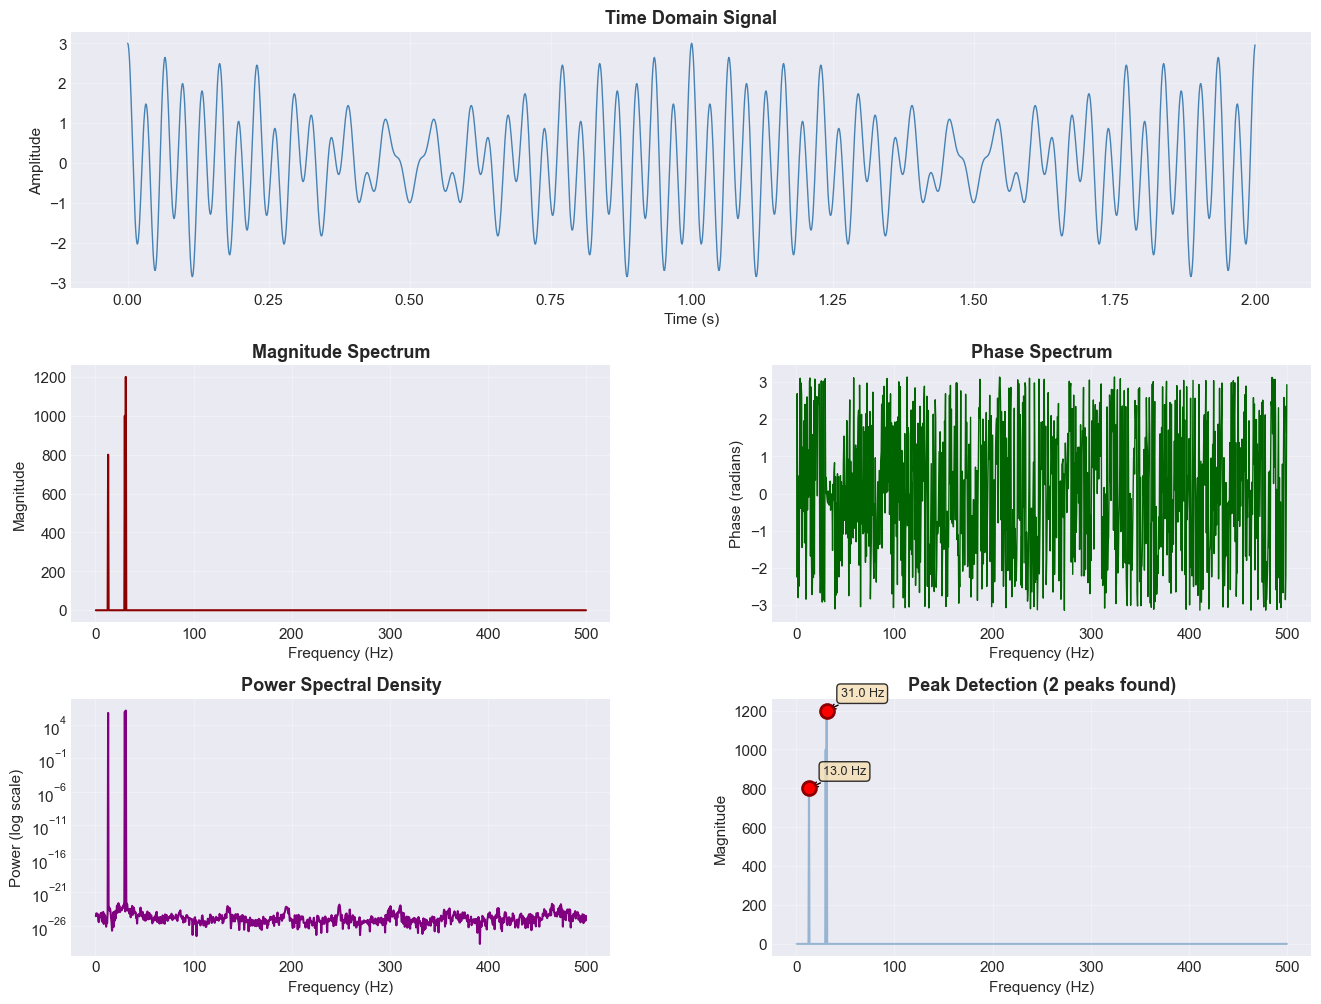


Identified vibrational frequencies:
Peak 1: 0.00 THz = 0 cm⁻¹ (magnitude: 800)
Peak 2: 0.00 THz = 0 cm⁻¹ (magnitude: 1200)


In [10]:
class FourierSpectrometer:
    """
    A complete Fourier Transform spectrometer for signal analysis
    """
    
    def __init__(self, signal, sample_rate, signal_type='general'):
        """
        Initialise the spectrometer
        
        Args:
            signal: Input signal array
            sample_rate: Sampling rate (Hz)
            signal_type: 'audio', 'molecular', or 'general'
        """
        self.signal = np.array(signal)
        self.sample_rate = sample_rate
        self.signal_type = signal_type
        self.N = len(signal)
        
        # Compute FFT
        self.fft_values = fft(signal)
        self.frequencies = fftfreq(self.N, 1/sample_rate)
        self.magnitude = np.abs(self.fft_values)
        self.phase = np.angle(self.fft_values)
        self.power = self.magnitude ** 2
        
        # Time array
        self.time = np.arange(self.N) / sample_rate
    
    def find_peaks(self, threshold=0.1, min_freq=0, max_freq=None):
        """
        Identify significant frequency peaks
        
        Args:
            threshold: Minimum relative magnitude (0-1)
            min_freq: Minimum frequency to consider
            max_freq: Maximum frequency to consider
            
        Returns:
            peak_freqs: Array of peak frequencies
            peak_mags: Array of peak magnitudes
        """
        if max_freq is None:
            max_freq = self.sample_rate / 2
        
        # Consider only positive frequencies in range
        mask = (self.frequencies > min_freq) & (self.frequencies < max_freq)
        
        # Normalise magnitude
        mag_norm = self.magnitude[mask] / np.max(self.magnitude[mask])
        freqs = self.frequencies[mask]
        
        # Find peaks above threshold
        peaks, properties = find_peaks(mag_norm, height=threshold, distance=10)
        
        peak_freqs = freqs[peaks]
        peak_mags = self.magnitude[mask][peaks]
        
        return peak_freqs, peak_mags
    
    def filter_frequencies(self, freq_range):
        """
        Band-pass filter: keep only frequencies in specified range
        
        Args:
            freq_range: Tuple of (min_freq, max_freq)
            
        Returns:
            filtered_signal: Filtered time-domain signal
        """
        fft_filtered = self.fft_values.copy()
        
        # Create mask
        mask = (np.abs(self.frequencies) < freq_range[0]) | \
               (np.abs(self.frequencies) > freq_range[1])
        
        fft_filtered[mask] = 0
        
        # Inverse FFT
        filtered_signal = np.real(ifft(fft_filtered))
        
        return filtered_signal
    
    def plot_complete_analysis(self, freq_range=None):
        """
        Create comprehensive visualisation of signal analysis
        
        Args:
            freq_range: Tuple of (min_freq, max_freq) for display
        """
        fig = plt.figure(figsize=(16, 12))
        gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)
        
        # 1. Time domain signal
        ax1 = fig.add_subplot(gs[0, :])
        plot_samples = min(5000, self.N)
        ax1.plot(self.time[:plot_samples], self.signal[:plot_samples], 
                'steelblue', linewidth=1)
        ax1.set_xlabel('Time (s)', fontsize=11)
        ax1.set_ylabel('Amplitude', fontsize=11)
        ax1.set_title('Time Domain Signal', fontsize=13, fontweight='bold')
        ax1.grid(True, alpha=0.3)
        
        # 2. Magnitude spectrum
        ax2 = fig.add_subplot(gs[1, 0])
        positive_idx = self.frequencies > 0
        
        if freq_range:
            freq_mask = (self.frequencies > freq_range[0]) & \
                       (self.frequencies < freq_range[1])
            plot_freqs = self.frequencies[freq_mask]
            plot_mags = self.magnitude[freq_mask]
        else:
            plot_freqs = self.frequencies[positive_idx]
            plot_mags = self.magnitude[positive_idx]
        
        ax2.plot(plot_freqs, plot_mags, 'darkred', linewidth=1.5)
        ax2.set_xlabel('Frequency (Hz)', fontsize=11)
        ax2.set_ylabel('Magnitude', fontsize=11)
        ax2.set_title('Magnitude Spectrum', fontsize=13, fontweight='bold')
        ax2.grid(True, alpha=0.3)
        
        # 3. Phase spectrum
        ax3 = fig.add_subplot(gs[1, 1])
        if freq_range:
            plot_phase = self.phase[freq_mask]
        else:
            plot_phase = self.phase[positive_idx]
        
        ax3.plot(plot_freqs, plot_phase, 'darkgreen', linewidth=1)
        ax3.set_xlabel('Frequency (Hz)', fontsize=11)
        ax3.set_ylabel('Phase (radians)', fontsize=11)
        ax3.set_title('Phase Spectrum', fontsize=13, fontweight='bold')
        ax3.grid(True, alpha=0.3)
        
        # 4. Power spectral density
        ax4 = fig.add_subplot(gs[2, 0])
        if freq_range:
            plot_power = self.power[freq_mask]
        else:
            plot_power = self.power[positive_idx]
        
        ax4.semilogy(plot_freqs, plot_power, 'purple', linewidth=1.5)
        ax4.set_xlabel('Frequency (Hz)', fontsize=11)
        ax4.set_ylabel('Power (log scale)', fontsize=11)
        ax4.set_title('Power Spectral Density', fontsize=13, fontweight='bold')
        ax4.grid(True, alpha=0.3, which='both')
        
        # 5. Identified peaks
        ax5 = fig.add_subplot(gs[2, 1])
        if freq_range:
            peak_freqs, peak_mags = self.find_peaks(
                threshold=0.1, min_freq=freq_range[0], max_freq=freq_range[1]
            )
        else:
            peak_freqs, peak_mags = self.find_peaks(threshold=0.1)
        
        ax5.plot(plot_freqs, plot_mags, 'steelblue', linewidth=1.5, alpha=0.5)
        ax5.scatter(peak_freqs, peak_mags, c='red', s=100, zorder=5,
                   marker='o', edgecolors='darkred', linewidths=2)
        
        # Label peaks
        for i, (f, m) in enumerate(zip(peak_freqs[:10], peak_mags[:10])):
            ax5.annotate(f'{f:.1f} Hz',
                        xy=(f, m), xytext=(10, 10),
                        textcoords='offset points', fontsize=9,
                        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
                        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0'))
        
        ax5.set_xlabel('Frequency (Hz)', fontsize=11)
        ax5.set_ylabel('Magnitude', fontsize=11)
        ax5.set_title(f'Peak Detection ({len(peak_freqs)} peaks found)', 
                     fontsize=13, fontweight='bold')
        ax5.grid(True, alpha=0.3)
        
        plt.show()
        
        return peak_freqs, peak_mags

# Test the spectrometer with our water vibrations
spectrometer = FourierSpectrometer(water_vib, sample_rate, signal_type='molecular')
peak_freqs, peak_mags = spectrometer.plot_complete_analysis(freq_range=(0, 2e14))

print("\nIdentified vibrational frequencies:")
for i, (f, m) in enumerate(zip(peak_freqs, peak_mags), 1):
    wavenumber = f / (2.998e10)
    print(f"Peak {i}: {f/1e12:.2f} THz = {wavenumber:.0f} cm⁻¹ (magnitude: {m:.0f})")

## Conclusion

We've journeyed from musical chords to molecular vibrations, all through the lens of the Fourier Transform. This mathematical tool transforms signals between time and frequency domains, revealing hidden patterns in data.

### Key Takeaways:

1. **Complex signals are sums of simple waves** - Any waveform can be decomposed into pure sine waves
2. **Fourier Transform reveals hidden frequencies** - It's a mathematical "prism" for signals
3. **Frequency domain enables powerful operations** - Filtering and analysis are often simpler
4. **Universal applicability** - Same mathematics for audio, light, molecular vibrations, quantum mechanics

The Fourier Transform bridges seemingly unrelated domains: music and medicine, radio and chemistry, image compression and astronomy. It's a testament to the unity of physical phenomena.

### Experiment Further:

- Try different musical chords (minor chords, seventh chords)
- Simulate other molecules (CO₂, NH₃, CH₄)
- Load real audio files and analyse them
- Implement different window functions (Hanning, Hamming, Blackman)
- Explore 2D Fourier Transforms for image processing

The code is yours to explore and extend. Happy signal processing!